# Plated in Gold: what drives Apple Watch resale list prices?

Final analysis notebook. Runs top to bottom using the `src` package; every figure is written to `../images/`.

**Question:** which product, seller and geographic factors are associated with higher or lower Apple Watch asking prices on resale marketplaces? *Caveat: these are list prices, not completed sales.*

## 1. Setup

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from src import IMAGES_DIR
from src.data import load_raw, load_clean
from src.modeling import FEATURES, FEATURES_PS
from src.story import compute_story, CURRENT_GEN
from src import visualization as viz
pd.set_option('display.max_colwidth', 80)
IMAGES_DIR.mkdir(exist_ok=True)

## 2. Data at a glance
Cleaning (`src/cleaning.py`): accents removed and titles lower-cased, Spanish condition/country labels mapped to English, prices above $2,000 dropped, Apple only, bundles/lots/iPhones removed, condition set to *New* when the title says “brand new” or “unopened”. Features (`src/features.py`): model, family, Hermès, cellular, titanium, 24k gold, premium band, ceramic, power seller (2+ listings).

In [2]:
raw = load_raw(); df = load_clean()
st = compute_story(raw, df); C = st['claims']
print(f"raw rows: {len(raw):,} | Apple share: {st['summary']['apple_share']}%")
pd.Series(st['summary'])

raw rows: 3,607 | Apple share: 65.71%


entries        2328.00
sellers        1430.00
countries        20.00
models           18.00
apple_share      65.71
raw_rows       3607.00
dtype: float64

In [3]:
df.sample(5, random_state=1)[['condition','case_size','country','price','seller_id','model','gold','hermes','power_seller','title']]

,condition,case_size,country,price,seller_id,model,gold,hermes,power_seller,title
2513,Used,49.0,United States,489.95,Seller_1208,Ultra 2,0,0,1,apple watch ultra 2 gps titanium blue alpine loop l a2986
2312,New,45.0,United States,500.00,Seller_1069,Series 9,0,0,0,apple watch series 9 graphite stainless steel
88,Open box,NaN,United States,997.00,Seller_0038,Series 7,1,0,1,gold plated apple watch 24k gold custom stainless steel series 7 white sport...
907,Open box,42.0,United States,699.00,Seller_0035,NaN,1,0,1,24k gold apple watch with leather etoupe double buckle cuff
1799,For parts or not working,NaN,United States,555.99,Seller_0806,Ultra 3,0,0,0,apple watch ultra 3 black titanium alpine loop ( m ) check esn


USA 77.36% | UK 9.11% | Ultra 50.02% | Series 46.8%


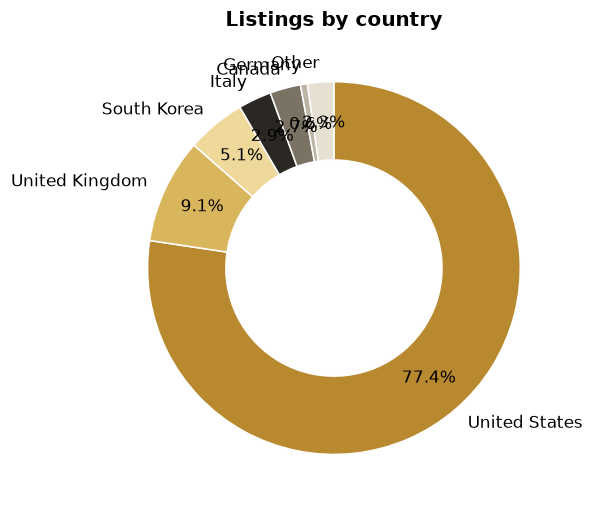

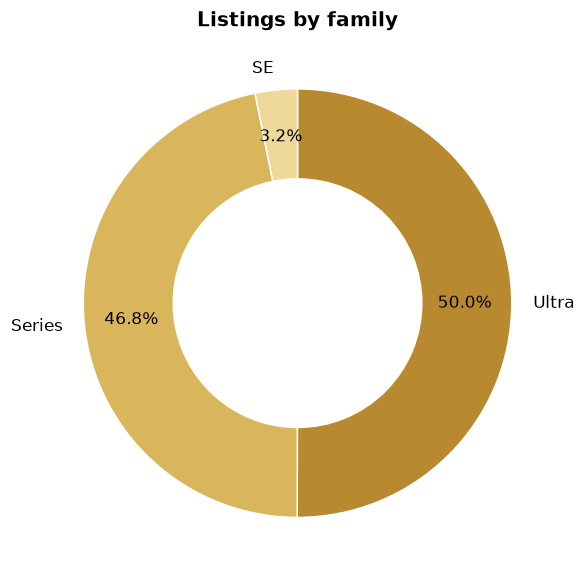

In [4]:
print(f"USA {C['us_share']}% | UK {C['uk_share']}% | Ultra {C['ultra_share']}% | Series {C['series_share']}%")
viz.fig_donut(df['country'].value_counts(), 'Listings by country', IMAGES_DIR/'01_country_donut.png'); plt.show()
viz.fig_donut(df['family'].value_counts(), 'Listings by family', IMAGES_DIR/'02_family_donut.png'); plt.show()

overall mean $577.5 | excluding UK $592.51 | UK lowest (30+ listings): True


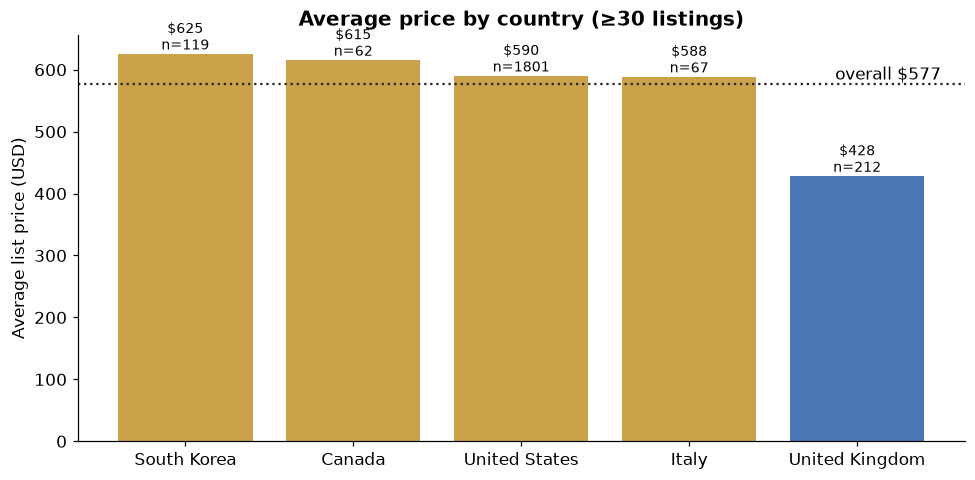

In [5]:
print(f"overall mean ${C['mean_all']} | excluding UK ${C['mean_ex_uk']} | UK lowest (30+ listings): {C['uk_lowest']}")
viz.fig_country_means(df, IMAGES_DIR/'03_country_means.png'); plt.show()

{'individual_mean': 561.44, 'power_mean': 596.34, 'n_ind': 1257, 'n_pow': 1071, 'pct_cheaper': 5.85, 'p': 5.095279214206558e-08}


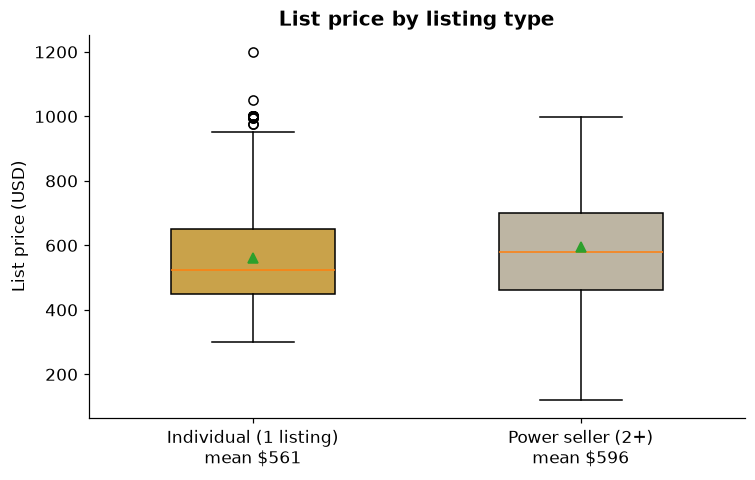

In [6]:
print(st['listing'])
viz.fig_listing_type(df, IMAGES_DIR/'04_listing_type.png'); plt.show()

## 3. The gold-plating pitfall

Models averaging more than the Ultra 3: ['Series 2', 'Series 4', 'Series 3'] | Ultra 3 rank 4


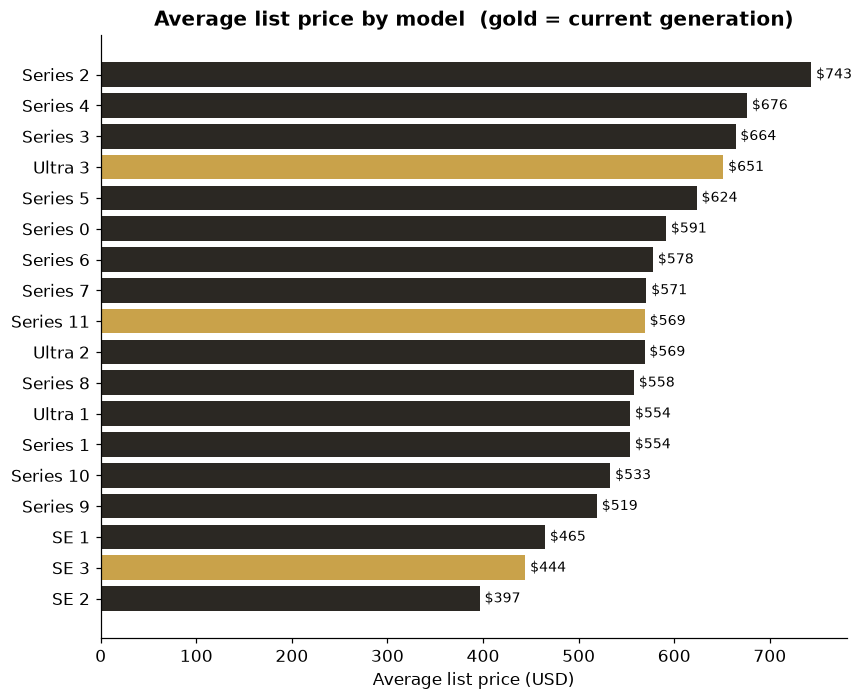

In [7]:
print('Models averaging more than the Ultra 3:', C['old_above_ultra3'], '| Ultra 3 rank', C['ultra3_rank'])
viz.fig_price_by_model(df, CURRENT_GEN, IMAGES_DIR/'05_price_by_model.png'); plt.show()

Highest gold share: ['Series 2', 'Series 4', 'Series 3'] | top-3 priced: ['Series 2', 'Series 4', 'Series 3'] | current-gen gold listings: 0
Gold premium within models (src.features.calculate_price_increase): {'dollar': 294, 'pct': 54.8, 'n': 123, 'with_': 810.86, 'without': 564.48}


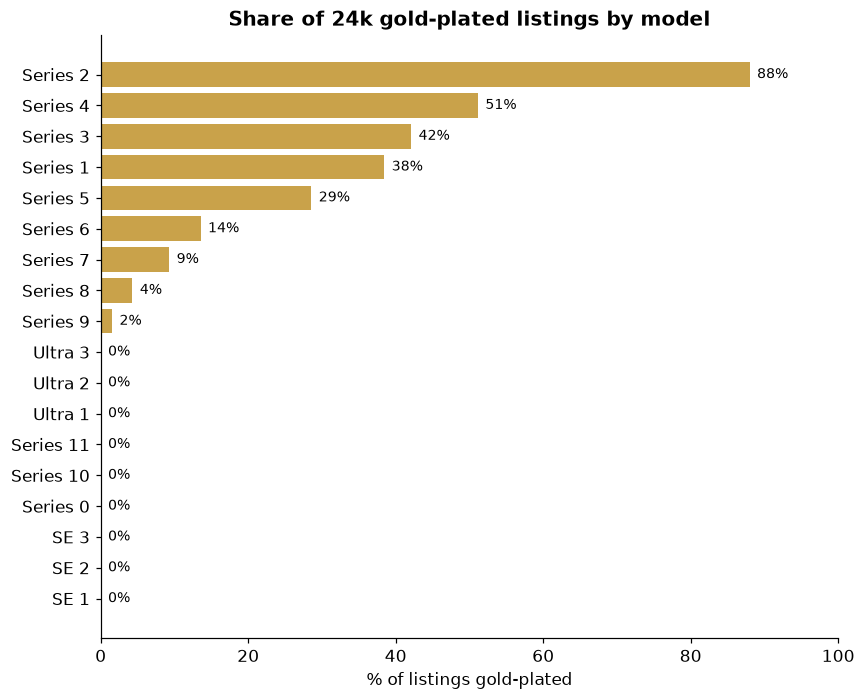

In [8]:
print('Highest gold share:', C['top3_gold'], '| top-3 priced:', C['top3_price'], '| current-gen gold listings:', C['current_gen_gold_n'])
print('Gold premium within models (src.features.calculate_price_increase):', st['gold'])
viz.fig_gold_share(df, IMAGES_DIR/'06_gold_share_by_model.png'); plt.show()

Without gold: Ultra 3 rank 1 | still above Series 11: ['Series 2', 'Series 3'] {'Series 2': 615.0, 'Series 3': 574.81, 'Series 4': 549.95, 'Ultra 3': 651.42, 'Series 11': 569.34}


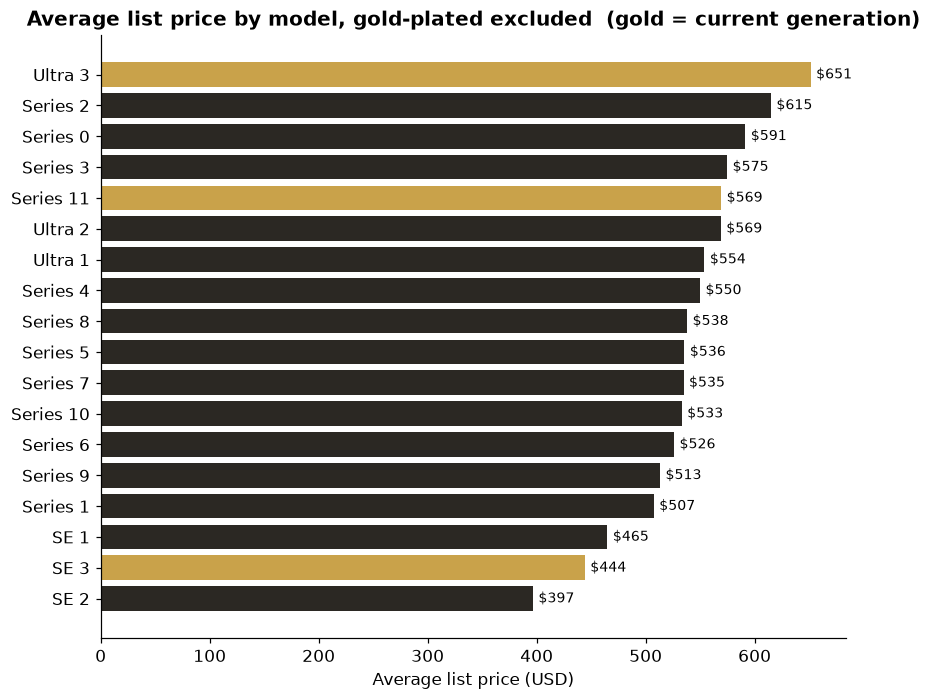

In [9]:
print('Without gold: Ultra 3 rank', C['ultra3_rank_std'], '| still above Series 11:', C['std_old_above_s11'], C['std_means'])
viz.fig_price_by_model(df[df.gold == 0], CURRENT_GEN, IMAGES_DIR/'07_price_by_model_no_gold.png', 'Average list price by model, gold-plated excluded'); plt.show()

## 4. Modeling: CatBoost
Rows with missing values dropped, 80/20 split (`random_state=43`), default `CatBoostRegressor()`, categorical features model/country/condition/seller_id (`src/modeling.py`).

In [10]:
pd.DataFrame({'11 features (headline)': st['metrics'], '+ power_seller': st['metrics_ps']})

,11 features (headline),+ power_seller
r2,0.5297,0.5248
mae,69.4000,70.0200
n_train,1585.0000,1585.0000
n_test,397.0000,397.0000


## 5. Explaining the model with SHAP

model                 26.94
country               21.09
condition             19.03
seller_id             18.13
case_size             12.07
worldwide_shipping    11.63
gold                   9.37
premium_band           6.97
hermes                 6.57
cellular               3.48
power_seller           2.83
ceramic                0.33
dtype: float64


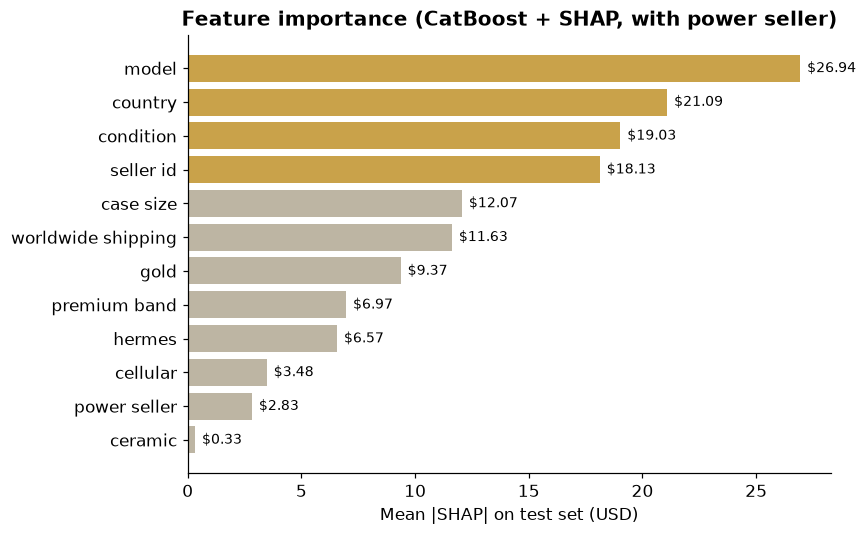

In [11]:
imp = st['A'].importance(); print(imp.round(2))
viz.fig_importance(imp.rename(lambda s: s.replace('_',' ')), 'Feature importance (CatBoost + SHAP, with power seller)', IMAGES_DIR/'08_shap_ranking.png'); plt.show()

typical Ultra 3 listing 1025 {'condition': 25.97, 'case_size': 13.81, 'worldwide_shipping': -7.69, 'country': 7.07, 'model': 62.08, 'hermes': -2.17, 'cellular': 0.7, 'gold': -8.05, 'premium_band': -4.87, 'ceramic': 0.14, 'seller_id': 0.53}


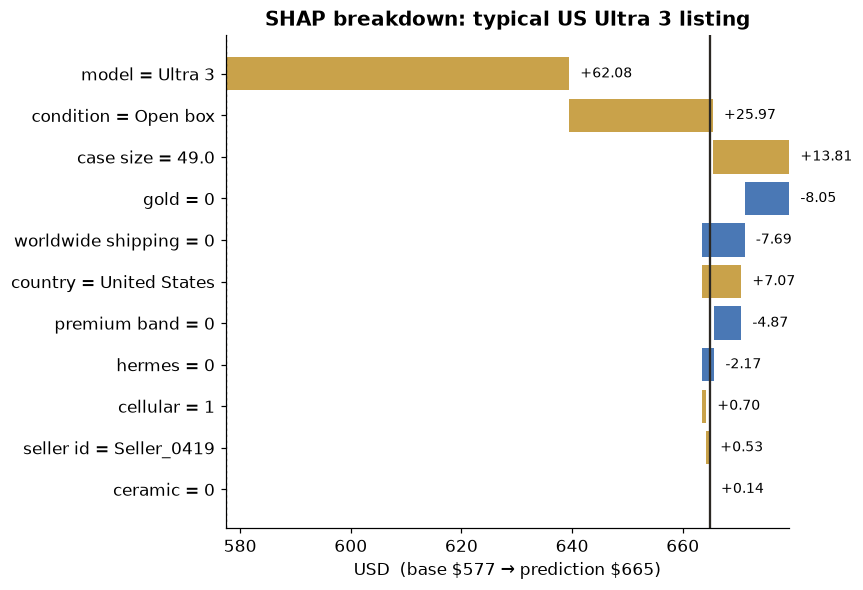

In [12]:
X = st['X']; lab = [f.replace('_',' ') for f in FEATURES]; ti = df.index.get_loc(st['typical_idx'])
print('typical Ultra 3 listing', st['typical_idx'], C['typical_shap'])
viz.fig_waterfall(st['sv'][ti], [f'{l} = {X.iloc[ti][f]}' for l, f in zip(lab, FEATURES)], st['base'], 'SHAP breakdown: typical US Ultra 3 listing', IMAGES_DIR/'09_shap_typical_ultra3.png'); plt.show()

Series 2 gold: gold 47.59 | model -25.76


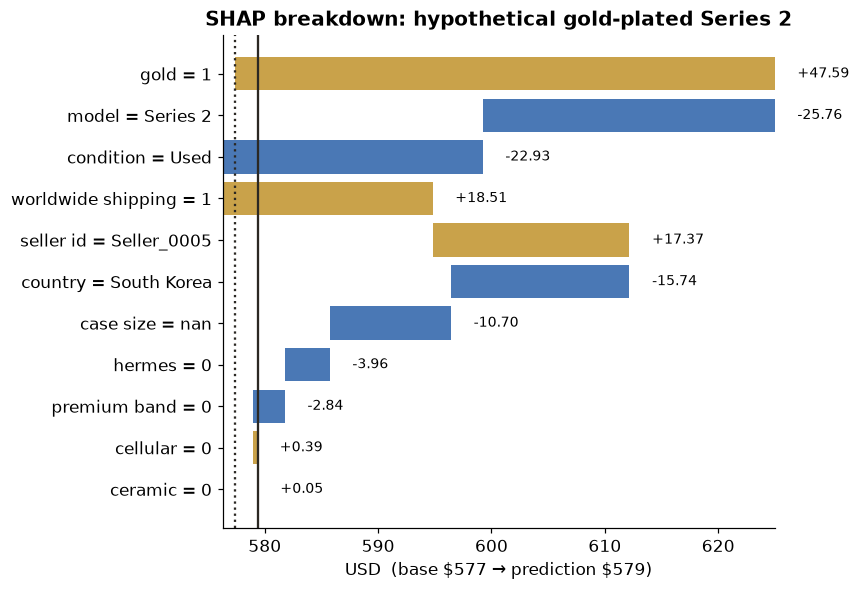

In [13]:
w = st['s2_row'].iloc[0]
print('Series 2 gold: gold', C['s2_gold_shap'], '| model', C['s2_model_shap'])
viz.fig_waterfall(st['s2_shap'], [f'{l} = {w[f]}' for l, f in zip(lab, FEATURES)], st['base'], 'SHAP breakdown: hypothetical gold-plated Series 2', IMAGES_DIR/'10_shap_series2_gold.png'); plt.show()

{'uk_mean': 427.61, 'rest_mean': 592.51, 'n': 212, 'p': 1.7502137443465684e-52, 'neg_all': 212, 'neg_test': 33, 'n_test': 33}
UK models below cross-country mean: 17 of 17


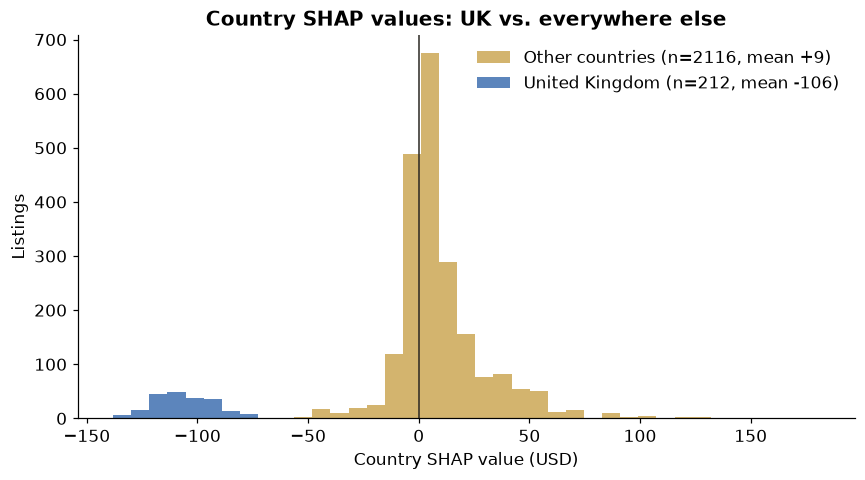

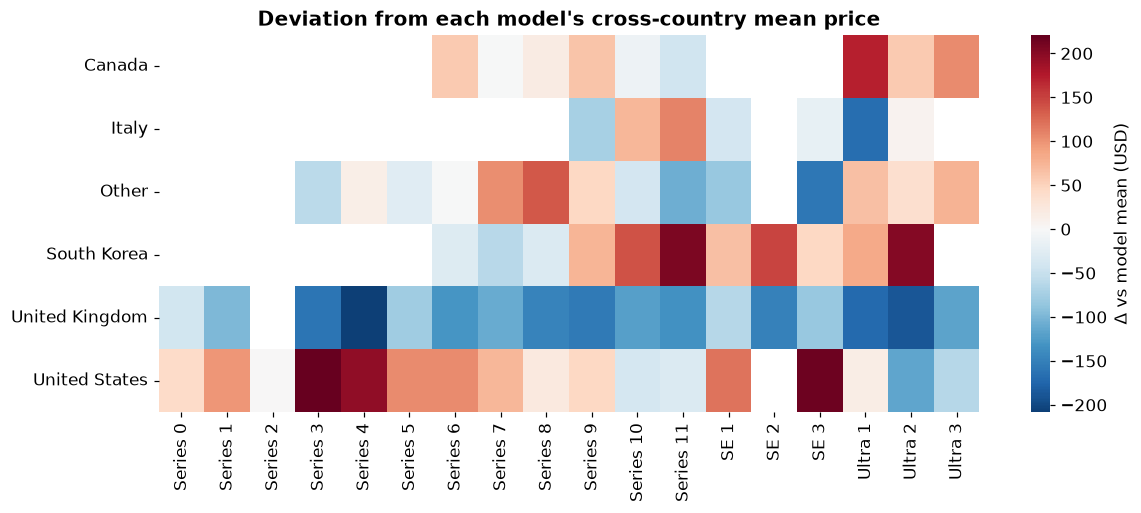

In [14]:
print(st['uk']); print('UK models below cross-country mean:', C['uk_models_below'], 'of', C['uk_models_total'])
viz.fig_country_shap(df['country'].values, st['sv'][:, FEATURES.index('country')], IMAGES_DIR/'11_shap_country_uk.png'); plt.show()
viz.fig_deviation_heatmap(df, IMAGES_DIR/'12_price_deviation_heatmap.png'); plt.show()

## 6. Key findings
1. **Model is the top feature, but raw averages mislead:** Series 2, 4 and 3 average more than the Ultra 3, and they have the highest gold-plating shares.
2. **Big niche effect, small global effect:** gold-plating carries a ~55% within-model premium but ranks 7th of 12 by mean |SHAP|.
3. **Country is a large source of variation:** UK listings sit below the cross-country mean in 17 of the 17 models listed there, and 212 of 212 UK listings get a negative country SHAP value.

See the printed values above; the README quotes these same numbers.